In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import geopandas as gpd

from dark_spots import build_dark_alljp
from weather import load_weather_station

In [2]:
dark_alljp = build_dark_alljp()

Loading formatted geocoded file...
本土4268 + 沖縄327 = 合計4595


In [3]:
dark_alljp.head()

,lat,lon,radiance,mpsas,bortle,country,prefecture,city
0,45.531250,141.952086,0.408587,21.700001,2.0,JP,Hokkaido,Makubetsu
1,45.527083,141.918753,0.408402,21.700001,2.0,JP,Hokkaido,Makubetsu
2,45.493750,141.868753,0.399477,21.719999,1.9,JP,Hokkaido,Makubetsu
3,45.489583,141.868753,0.386844,21.750000,1.7,JP,Hokkaido,Makubetsu
4,45.485416,141.868753,0.367310,21.809999,1.4,JP,Hokkaido,Makubetsu


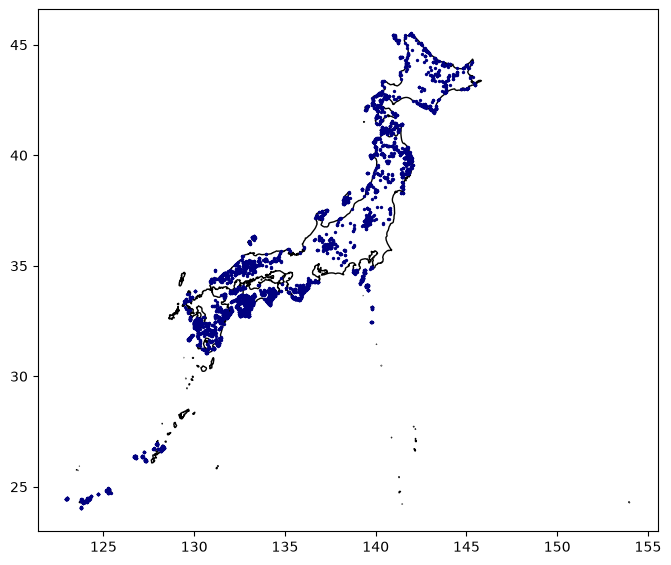

In [ ]:
# lat/lon から geometry(点)を作って、GeoDataFrameにする
gdf = gpd.GeoDataFrame(
    dark_alljp,
    geometry=gpd.points_from_xy(dark_alljp['lon'], dark_alljp['lat']),
    crs="EPSG:4326"   # ← 緯度経度の座標系を表示 CRS（Coordinate Reference System：座標参照系
)

# 世界の地図データを取得(GeoPandas内蔵 or ネットから)
world = gpd.read_file("https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_0_countries.zip")
japan = world[world['NAME'] == 'Japan']

# 重ねて描く
fig, ax = plt.subplots(figsize=(8, 10))
japan.plot(ax=ax, color='white', edgecolor='black')   # 下:白地図
gdf.plot(ax=ax, markersize=2, color='navy')            # 上:暗い点
plt.show()

In [5]:
active_station_df = load_weather_station()

In [10]:
active_station_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1286 entries, 0 to 1285
Data columns (total 29 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Station Number                        1286 non-null   int64  
 1   Station Name(Kanji)                   1286 non-null   str    
 2   Station Name(Kana)                    1286 non-null   str    
 3   Station Name                          1286 non-null   str    
 4   Station Name of Snow(Kanji)           334 non-null    str    
 5   Station Name of Snow(Kana)            334 non-null    str    
 6   Station Name of Snow                  334 non-null    str    
 7   Latitude_Precipitation(degree)        1286 non-null   float64
 8   Longitude_Precipitation(degree)       1286 non-null   float64
 9   Altitude_Precipitation(m)             1286 non-null   int64  
 10  Height of Anemometer(m)               915 non-null    float64
 11  Latitude_Snow(degree)       

In [12]:
print("日照時間:", (active_station_df['Sunshine Duration'] == 1).sum(), "地点")
print("湿度:", (active_station_df['Humidity'] == 1).sum(), "地点")
print("降水量:", (active_station_df['Precipitation'] == 1).sum(), "地点")

日照時間: 155 地点
湿度: 589 地点
降水量: 1285 地点


In [13]:
active_station_df[active_station_df['Precipitation'] == 0]

,Station Number,Station Name(Kanji),Station Name(Kana),Station Name,Station Name of Snow(Kanji),Station Name of Snow(Kana),Station Name of Snow,Latitude_Precipitation(degree),Longitude_Precipitation(degree),Altitude_Precipitation(m),...,Humidity,Start Date,End Date,Old Station Number,Disconnection of Precipitation,Disconnection of Wind Speed,Disconnection of Temperature,Disconnection of Sunshine Duration,Disconnection of Depth of Snow Cover,Disconnection of Humidity
614,50066,富士山,フジサン,FUJISAN,NaN,NaN,NaN,35.36,138.727,3775,...,1,2021-03-02,9999-99-99,50066,0,0,0,0,0,0


### 天気項目

- 湿度589 → 西日本中心にそこそこ分布 → 補助として採用
- 降水量1285 → ほぼ全国 → 主役として採用

### サンプルで確認する

In [14]:
with open('sample_jma_data.csv', encoding='shift_jis') as f:
    for i, line in enumerate(f):
        if i < 8:
            print(i, ':', line.strip()) 

0 : ダウンロードした時刻：2026/08/16 12:12:58
1 : 
2 : ,釧路,釧路,釧路,釧路,釧路,釧路,釧路,釧路,釧路,釧路,湯沢,湯沢,湯沢,湯沢,湯沢,湯沢,湯沢,湯沢,湯沢,奥日光（日光）,奥日光（日光）,奥日光（日光）,奥日光（日光）,奥日光（日光）,奥日光（日光）,奥日光（日光）,奥日光（日光）,奥日光（日光）,奥日光（日光）,七尾,七尾,七尾,七尾,七尾,七尾,七尾,七尾,七尾,新宮,新宮,新宮,新宮,新宮,新宮,新宮,新宮,新宮,津山,津山,津山,津山,津山,津山,津山,津山,津山,津山,近永,近永,近永,近永,近永,近永,近永,近永,近永,宿毛,宿毛,宿毛,宿毛,宿毛,宿毛,宿毛,宿毛,宿毛,宿毛,中村,中村,中村,中村,中村,中村,中村,中村,中村,豊後高田,豊後高田,豊後高田,豊後高田,豊後高田,豊後高田,豊後高田,豊後高田,豊後高田
3 : 年月日,平均湿度(％),平均湿度(％),平均湿度(％),降水量の合計(mm),降水量の合計(mm),降水量の合計(mm),降水量の合計(mm),平均気温(℃),平均気温(℃),平均気温(℃),平均湿度(％),平均湿度(％),平均湿度(％),降水量の合計(mm),降水量の合計(mm),降水量の合計(mm),平均気温(℃),平均気温(℃),平均気温(℃),平均湿度(％),平均湿度(％),平均湿度(％),降水量の合計(mm),降水量の合計(mm),降水量の合計(mm),降水量の合計(mm),平均気温(℃),平均気温(℃),平均気温(℃),平均湿度(％),平均湿度(％),平均湿度(％),降水量の合計(mm),降水量の合計(mm),降水量の合計(mm),平均気温(℃),平均気温(℃),平均気温(℃),平均湿度(％),平均湿度(％),平均湿度(％),降水量の合計(mm),降水量の合計(mm),降水量の合計(mm),平均気温(℃),平均気温(℃),平均気温(℃),平均湿度(％),平均湿度(％),平均湿度(％),降水量の合計(mm),降水量の合計(mm),降水量の合計(mm),降水量の合計(mm),平均気温(℃),平均気温(℃),平均気温(℃),平均湿度(％),平均湿度(％),平均湿度(％),降水量の合計(mm),降水量の合計(mm),降水量の合計(mm),平均気温(℃),平均気温(℃),平均気温(

In [15]:
sample_weather_monthly = pd.read_csv('sample_jma_month_data.csv',encoding='shift_jis', header=[1,2])
sample_weather_monthly.drop(0, inplace=True)
sample_weather_monthly.head()

Unnamed: 0_level_0      釧路                                              \
                  年月 平均湿度(％) 平均湿度(％).1 平均湿度(％).2 降水量の合計(mm) 降水量の合計(mm).1   
1             2005/1    65.0         8         1       11.5            0   
2             2005/2    64.0         8         1       26.5            0   
3             2005/3    66.0         8         1       75.5            0   
4             2005/4    71.0         8         1       99.5            0   
5             2005/5    78.0         8         1      103.5            0   

                                               ...        中村    豊後高田  \
  降水量の合計(mm).2 降水量の合計(mm).3 平均気温(℃) 平均気温(℃).1  ... 平均気温(℃).2 平均湿度(％)   
1            8            1    -4.3         8  ...         1     NaN   
2            8            1    -4.9         8  ...         1     NaN   
3            8            1    -1.0         8  ...         1     NaN   
4            8            1     4.0         8  ...         1     NaN   
5            8            1     6.6         8  ...         1     NaN   

                                                                              \
  平均湿度(％).1 平均湿度(％).2 降水量の合計(mm) 降水量の合計(mm).1 降水量の合計(mm).2 平均気温(℃) 平均気温(℃).1   
1         0         1       34.0            8            1     5.0         8   
2         0         1       84.0            8            1     4.8         8   
3         0         1       63.0            8            1     8.0         8   
4         0         1       26.0            8            1    14.8         8   
5         0         1       68.0            8            1    18.4         8   

             
  平均気温(℃).2  
1         1  
2         1  
3         1  
4         1  
5         1  

[5 rows x 95 columns]